# Notebook 06 — Modelo Digital del Terreno (MDT)

**Objetivo**: incorporar la capa de **topografía** al sistema, imprescindible para cualquier modelo de inundación. La elevación determina dónde se acumula el agua, y la pendiente cómo de rápido fluye.

**Fuente**: MDT25 (paso de malla 25 m) del Instituto Geográfico Nacional (IGN), 2ª cobertura. Descargado del Centro Nacional de Información Geográfica (CNIG).

**Hojas descargadas** (4 cuartos del MTN50):
- `0721-1`, `0721-2` → cabecera del barranco del Poyo (Chiva, Cheste)
- `0722-1`, `0722-3` → Valencia + zona inundada (Catarroja, Paiporta)

**Estructura del notebook**:
1. Inspección individual de cada fichero TIF.
2. Mosaico de las 4 hojas en un único raster.
3. Reproyección a WGS84 (lat/lon) para integración con Folium.
4. Mapa de relieve sombreado (hillshade) — Figura 5.4 de la memoria.
5. Superposición de las estaciones SAIH del 29-oct sobre el relieve.
6. Cálculo de pendiente como feature del modelo predictivo.

## 1. Inspección de cada fichero TIF

Antes de procesarlos, miramos qué hay dentro de cada uno: dimensiones, sistema de coordenadas, rango de elevaciones, etc.

In [25]:
import rasterio
from pathlib import Path

dir_mdt = Path("../data/raw/mdt")
ficheros = sorted(dir_mdt.glob("*.TIF")) + sorted(dir_mdt.glob("*.tif"))
ficheros = sorted(set(ficheros))

print(f"Ficheros encontrados: {len(ficheros)}\n")

for f in ficheros:
    with rasterio.open(f) as src:
        print(f"=== {f.name} ===")
        print(f"  Dimensiones: {src.width} x {src.height} píxeles")
        print(f"  Resolución: {src.res[0]:.1f} m/píxel")
        print(f"  CRS: {src.crs}")
        print(f"  Extensión geográfica: {src.bounds}")
        # Leemos una muestra para ver el rango de elevaciones
        data = src.read(1, masked=True)
        print(f"  Elevación: {data.min():.1f} a {data.max():.1f} m sobre el nivel del mar")
        print()

Ficheros encontrados: 8

=== MDT25-ETRS89-H30-0721-1-COB2.tif ===
  Dimensiones: 587 x 388 píxeles
  Resolución: 25.0 m/píxel
  CRS: EPSG:3042
  Extensión geográfica: BoundingBox(left=684449.0, bottom=4365169.0, right=699124.0, top=4374869.0)
  Elevación: 201.9 a 958.3 m sobre el nivel del mar

=== MDT25-ETRS89-H30-0721-2-COB2.tif ===
  Dimensiones: 588 x 390 píxeles
  Resolución: 25.0 m/píxel
  CRS: EPSG:3042
  Extensión geográfica: BoundingBox(left=698779.0, bottom=4365499.0, right=713479.0, top=4375249.0)
  Elevación: 55.2 a 344.4 m sobre el nivel del mar

=== MDT25-ETRS89-H30-0721-3-COB2.tif ===
  Dimensiones: 588 x 388 píxeles
  Resolución: 25.0 m/píxel
  CRS: EPSG:3042
  Extensión geográfica: BoundingBox(left=684669.0, bottom=4355919.0, right=699369.0, top=4365619.0)
  Elevación: 172.1 a 725.6 m sobre el nivel del mar

=== MDT25-ETRS89-H30-0721-4-COB2.tif ===
  Dimensiones: 588 x 390 píxeles
  Resolución: 25.0 m/píxel
  CRS: EPSG:3042
  Extensión geográfica: BoundingBox(left=6990

**Qué leer en esta salida**:
- Dimensiones del orden de 400x400 píxeles cada uno (cuarto de hoja MTN50 a resolución 25 m).
- CRS = ETRS89/UTM 30N (EPSG:25830). Las coordenadas están en metros, no en grados. Tendremos que reproyectarlas a WGS84 (EPSG:4326) más adelante para usarlas con Folium.
- Las elevaciones van desde el nivel del mar (Valencia costa, ~0 m) hasta los picos de la cabecera (~1000-1200 m en la Sierra de Chiva/Buñol).

## 2. Mosaico de las 4 hojas en un único raster

Cada fichero `.TIF` cubre un cuarto de hoja MTN50. Para trabajar con todos como una sola unidad, los unimos con `rasterio.merge`. Esto genera un raster grande que cubre toda la zona de estudio.

In [26]:
import rasterio
from rasterio.merge import merge
import numpy as np

# Abrimos los 4 ficheros
src_files = [rasterio.open(f) for f in ficheros]

# rasterio.merge une todos los rásters
mosaico, transform_mosaico = merge(src_files)

print(f"Forma del mosaico: {mosaico.shape}")
print(f"  (1 banda, {mosaico.shape[1]} filas, {mosaico.shape[2]} columnas)")

# Guardamos el mosaico como un nuevo COG en data/interim/
out_path = Path("../data/interim/mdt_dana_utm30.tif")
out_path.parent.mkdir(parents=True, exist_ok=True)

# Copiamos metadatos del primer fichero y actualizamos para el mosaico
meta = src_files[0].meta.copy()
meta.update({
    "driver": "GTiff",
    "height": mosaico.shape[1],
    "width": mosaico.shape[2],
    "transform": transform_mosaico,
    "compress": "deflate",   # comprimir para que pese menos
})

with rasterio.open(out_path, "w", **meta) as dst:
    dst.write(mosaico)

# Cerramos los ficheros fuente
for f in src_files:
    f.close()

print(f"\nMosaico guardado: {out_path}")
print(f"Tamaño: {out_path.stat().st_size / 1024:.1f} KB")

Forma del mosaico: (1, 807, 2321)
  (1 banda, 807 filas, 2321 columnas)

Mosaico guardado: ..\data\interim\mdt_dana_utm30.tif
Tamaño: 4800.6 KB


## 3. Reproyección a WGS84

El mosaico está en proyección **ETRS89 / UTM zona 30N** (coordenadas en metros). Para integrarlo con Folium (que usa lat/lon en grados WGS84), lo reproyectamos. Ten en cuenta que esto cambia ligeramente los píxeles: pasamos de una rejilla en metros a otra en grados.

In [27]:
from rasterio.warp import calculate_default_transform, reproject, Resampling

src_path = Path("../data/interim/mdt_dana_utm30.tif")
dst_path = Path("../data/interim/mdt_dana_wgs84.tif")

with rasterio.open(src_path) as src:
    # Calculamos la transformación para reproyectar a WGS84 (EPSG:4326)
    transform, width, height = calculate_default_transform(
        src.crs, "EPSG:4326",
        src.width, src.height,
        *src.bounds
    )
    
    meta = src.meta.copy()
    meta.update({
        "crs": "EPSG:4326",
        "transform": transform,
        "width": width,
        "height": height,
    })
    
    with rasterio.open(dst_path, "w", **meta) as dst:
        reproject(
            source=rasterio.band(src, 1),
            destination=rasterio.band(dst, 1),
            src_transform=src.transform,
            src_crs=src.crs,
            dst_transform=transform,
            dst_crs="EPSG:4326",
            resampling=Resampling.bilinear,  # interpolación suave
        )

print(f"Reproyección completada.")
print(f"  Archivo: {dst_path}")

# Verificamos el resultado
with rasterio.open(dst_path) as src:
    print(f"  Dimensiones: {src.width} x {src.height}")
    print(f"  CRS: {src.crs}")
    print(f"  Bounding box (lat/lon): {src.bounds}")

Reproyección completada.
  Archivo: ..\data\interim\mdt_dana_wgs84.tif
  Dimensiones: 2403 x 693
  CRS: EPSG:4326
  Bounding box (lat/lon): BoundingBox(left=-0.859929571899925, bottom=39.31868749956814, right=-0.18009291336810185, top=39.514745262515525)


## 4. Mapa de relieve sombreado (hillshade)

Un MDT a pelo se ve como un mapa de tonos grises poco informativo. El truco para que se entienda visualmente es aplicar **hillshade** (sombreado del relieve): se simula un sol en una posición concreta y se calcula la sombra que proyecta cada ladera. El resultado es un mapa de aspecto **3D** muy intuitivo.

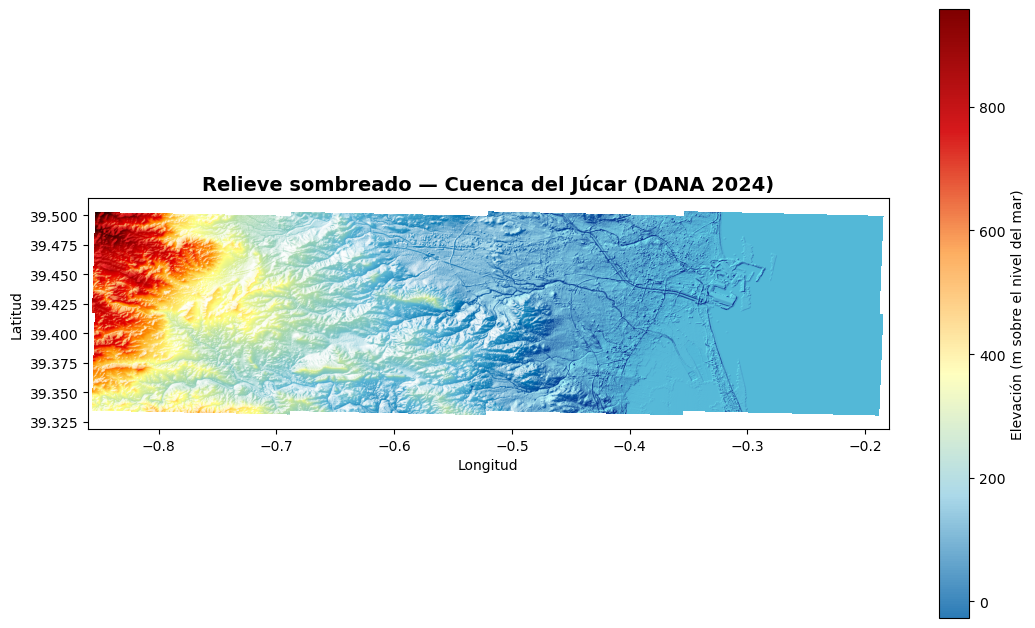

Imagen guardada: ..\data\processed\relieve_dana.png


In [28]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import LightSource, LinearSegmentedColormap

# Leemos el mosaico reproyectado
with rasterio.open(dst_path) as src:
    dem = src.read(1, masked=True)
    bounds = src.bounds

# Calculamos el hillshade (simulación de iluminación)
ls = LightSource(azdeg=315, altdeg=45)  # luz desde el NO, 45° de altura

# Combinamos el sombreado con un mapa de colores típico de altimetría
cmap_terreno = LinearSegmentedColormap.from_list(
    "terreno", 
    ["#2c7bb6", "#abd9e9", "#ffffbf", "#fdae61", "#d7191c", "#7f0000"]
)

# np.asarray para que LightSource trabaje con datos limpios (no masked)
dem_array = np.where(dem.mask, np.nan, dem.data) if hasattr(dem, "mask") else dem

# Aplicamos el sombreado al mapa de colores
rgb = ls.shade(dem_array, cmap=cmap_terreno, blend_mode="overlay",
               vmin=np.nanmin(dem_array), vmax=np.nanmax(dem_array))

# Pintamos
fig, ax = plt.subplots(figsize=(11, 9))
img = ax.imshow(rgb, extent=[bounds.left, bounds.right, bounds.bottom, bounds.top])
ax.set_title("Relieve sombreado — Cuenca del Júcar (DANA 2024)", fontsize=14, fontweight="bold")
ax.set_xlabel("Longitud")
ax.set_ylabel("Latitud")

# Añadimos barra de colores manual (porque rgb es ya una imagen procesada)
sm = plt.cm.ScalarMappable(cmap=cmap_terreno, norm=plt.Normalize(
    vmin=np.nanmin(dem_array), vmax=np.nanmax(dem_array)))
cbar = plt.colorbar(sm, ax=ax, shrink=0.7)
cbar.set_label("Elevación (m sobre el nivel del mar)")

plt.tight_layout()
out_img = Path("../data/processed/relieve_dana.png")
plt.savefig(out_img, dpi=150, bbox_inches="tight")
plt.show()

print(f"Imagen guardada: {out_img}")

**Lectura del relieve**: verás claramente la cabecera de cuenca al **oeste** (zonas rojas y marrones, >800 m) y el descenso hacia el llano costero al **este** (azules, 0-50 m). Entre medias, la franja donde se desarrolló la avenida: el barranco del Poyo conecta la cabecera con el llano. **El gradiente de elevación es la razón física por la que la lluvia que cayó en Chiva acabó arrasando Paiporta**.

Esta imagen es la **Figura 5.4 de tu memoria**.

## 5. Superposición de pluviómetros SAIH sobre el relieve

Ahora viene el plato fuerte: **ponemos las estaciones SAIH-CHJ del 29 de octubre sobre el mapa de relieve**, con el tamaño y color de los círculos proporcional a los mm caídos. Vas a ver cómo la lluvia extrema cayó justamente en las zonas elevadas de cabecera y nada en la costa donde ocurrieron las muertes.

Estaciones SAIH dentro del área del MDT (29-oct): 5


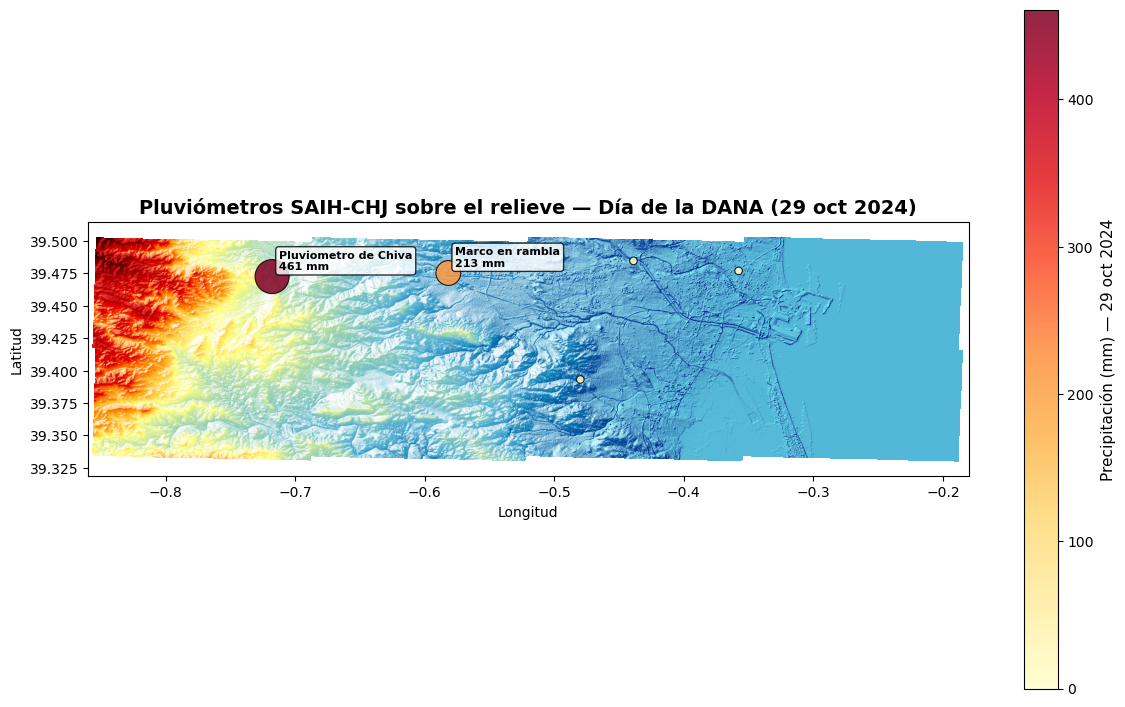

Imagen guardada: ..\data\processed\relieve_dana_con_pluviometros.png


In [29]:
import pandas as pd

# Cargamos las estaciones SAIH geolocalizadas para el 29 de octubre
saih_geo = pd.read_parquet("../data/processed/saih_geolocalizado_2020_2024.parquet")
dia_dana = saih_geo[
    (saih_geo["fecha"] == "2024-10-29") & saih_geo["lat"].notna()
].copy()

# Filtramos solo las estaciones DENTRO del área del MDT
dentro = (
    (dia_dana["lon"] >= bounds.left) & (dia_dana["lon"] <= bounds.right) &
    (dia_dana["lat"] >= bounds.bottom) & (dia_dana["lat"] <= bounds.top)
)
estaciones_zona = dia_dana[dentro].copy()
print(f"Estaciones SAIH dentro del área del MDT (29-oct): {len(estaciones_zona)}")

# Repintamos el relieve y añadimos las estaciones
fig, ax = plt.subplots(figsize=(12, 10))
ax.imshow(rgb, extent=[bounds.left, bounds.right, bounds.bottom, bounds.top])

# Función de escalado de tamaño según mm
def tamaño_marker(mm):
    return max(30, min(600, mm * 1.5))

# Pintamos las estaciones
scatter = ax.scatter(
    estaciones_zona["lon"],
    estaciones_zona["lat"],
    s=[tamaño_marker(mm) for mm in estaciones_zona["precipitacion_mm"]],
    c=estaciones_zona["precipitacion_mm"],
    cmap="YlOrRd",
    edgecolor="black",
    linewidth=0.8,
    alpha=0.85,
    vmin=0,
    vmax=estaciones_zona["precipitacion_mm"].max(),
)

# Etiquetas para las estaciones con más de 100 mm
for _, row in estaciones_zona[estaciones_zona["precipitacion_mm"] > 100].iterrows():
    # Extraemos un nombre corto de la descripción (primera palabra significativa)
    palabras = row["descripcion"].split()
    nombre_corto = " ".join(palabras[:3]) if len(palabras) > 2 else row["descripcion"]
    ax.annotate(
        f"{nombre_corto}\n{row['precipitacion_mm']:.0f} mm",
        xy=(row["lon"], row["lat"]),
        xytext=(5, 5),
        textcoords="offset points",
        fontsize=8,
        fontweight="bold",
        bbox=dict(boxstyle="round,pad=0.3", facecolor="white", edgecolor="black", alpha=0.8),
    )

cbar = plt.colorbar(scatter, ax=ax, shrink=0.7)
cbar.set_label("Precipitación (mm) — 29 oct 2024", fontsize=11)

ax.set_title("Pluviómetros SAIH-CHJ sobre el relieve — Día de la DANA (29 oct 2024)",
             fontsize=14, fontweight="bold")
ax.set_xlabel("Longitud")
ax.set_ylabel("Latitud")

plt.tight_layout()
out_img2 = Path("../data/processed/relieve_dana_con_pluviometros.png")
plt.savefig(out_img2, dpi=150, bbox_inches="tight")
plt.show()

print(f"Imagen guardada: {out_img2}")

**Lectura combinada del mapa relieve + pluviómetros**:

Esta imagen sintetiza visualmente el problema de tu TFM:

1. **Donde cayó la lluvia** (círculos rojos/naranjas) está en zonas elevadas del oeste: la cabecera de cuenca.
2. **Donde se produjeron las muertes** (Paiporta, Catarroja, Sedaví) está en el llano costero del este, casi sin círculos coloreados.
3. **La transición entre las dos zonas** es el barranco del Poyo, que canalizó el agua de un sitio a otro.

Si en lugar de mirar SOLO los pluviómetros (como hace AEMET) o SOLO el relieve, los combinas, **entiendes el evento completo**. Esto es exactamente lo que hace tu sistema multifuente.

Esta es probablemente la imagen más explicativa del Cap. 5.

## 6. Cálculo de pendiente como variable predictiva

Para el modelo predictivo necesitamos derivar **variables topográficas** del MDT. La pendiente es la más básica y útil: indica cómo de rápido fluye el agua sobre una ladera. Pendientes altas → escorrentía rápida → riesgo de avenida. Pendientes bajas → acumulación, encharcamiento.

Calculamos la pendiente y la guardamos como otra capa raster.

Pendiente: min=0.0°, max=65.2°, media=4.5°


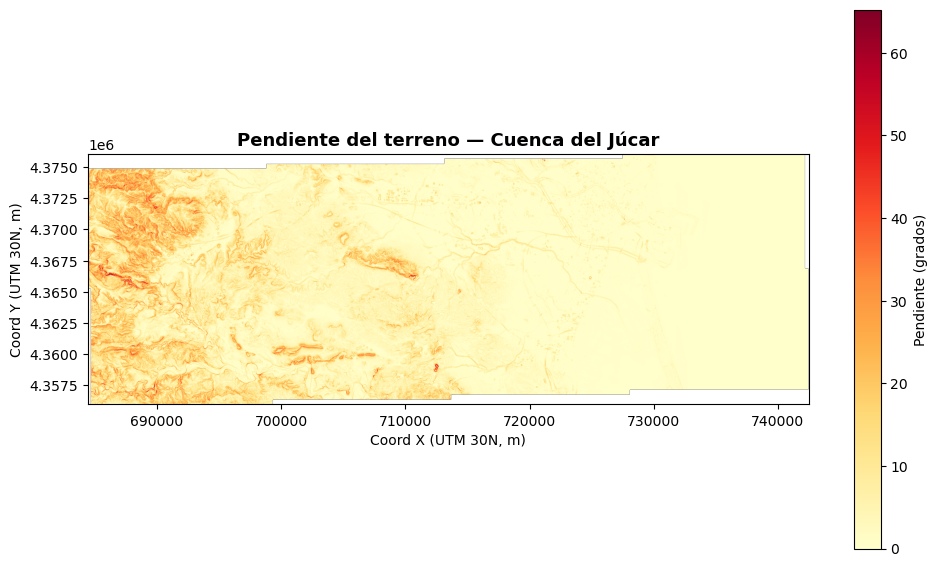


Pendiente guardada: ..\data\interim\pendiente_dana_utm30.tif


In [30]:
import numpy as np
from scipy import ndimage

# Leemos el DEM original (en UTM, donde las distancias están en metros)
with rasterio.open(src_path) as src:
    dem = src.read(1, masked=True).filled(np.nan)
    res = src.res[0]  # tamaño de píxel en metros (25 m)
    profile_pendiente = src.profile.copy()

# Gradientes en X y en Y (en metros por píxel)
dy, dx = np.gradient(dem, res)

# Pendiente en grados (atan de la magnitud del gradiente)
pendiente_grados = np.degrees(np.arctan(np.sqrt(dx**2 + dy**2)))

print(f"Pendiente: min={np.nanmin(pendiente_grados):.1f}°, "
      f"max={np.nanmax(pendiente_grados):.1f}°, "
      f"media={np.nanmean(pendiente_grados):.1f}°")

# Visualización
fig, ax = plt.subplots(figsize=(10, 8))
im = ax.imshow(pendiente_grados, cmap="YlOrRd",
               extent=[src.bounds.left, src.bounds.right, src.bounds.bottom, src.bounds.top])
ax.set_title("Pendiente del terreno — Cuenca del Júcar", fontsize=13, fontweight="bold")
ax.set_xlabel("Coord X (UTM 30N, m)")
ax.set_ylabel("Coord Y (UTM 30N, m)")
plt.colorbar(im, ax=ax, label="Pendiente (grados)", shrink=0.7)
plt.tight_layout()
plt.savefig("../data/processed/pendiente_dana.png", dpi=150, bbox_inches="tight")
plt.show()

# Guardamos la pendiente como raster
out_slope = Path("../data/interim/pendiente_dana_utm30.tif")
profile_pendiente.update({"dtype": "float32", "compress": "deflate"})
with rasterio.open(out_slope, "w", **profile_pendiente) as dst:
    dst.write(pendiente_grados.astype("float32"), 1)

print(f"\nPendiente guardada: {out_slope}")

## Conclusiones del notebook

1. **Capa topográfica integrada**: el MDT25 cubre el área de estudio con resolución de 25 m, suficiente para análisis a escala de cuenca.
2. **Visualización clave**: el mapa de relieve con pluviómetros superpuestos explica visualmente la dinámica del evento DANA — lluvia en cabecera (oeste, elevado) → avenida en costa (este, llano).
3. **Variable derivada**: pendiente del terreno calculada y guardada como raster, lista para incorporarse al modelo predictivo.

**Próximos pasos del trabajo**:
- Bloque A3: Productos Copernicus EMS (validación de la huella real de inundación).
- Bloque B: feature engineering y modelo XGBoost.
- Bloque C: streaming Kafka + Spark y dashboard.